# TP 2 : Histogramme et Seuillage d’Image

### Exercice 1: Étude de l’histogramme
1. Afficher et analyser l’histogramme d’une image donnée.
2. Appliquer un étirement linéaire et comparer l’effet sur le contraste.
3. Appliquer une égalisation d’histogramme et comparer avec l’étirement.

In [19]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

In [20]:
image_origine = cv2.imread("image.png", cv2.IMREAD_GRAYSCALE)

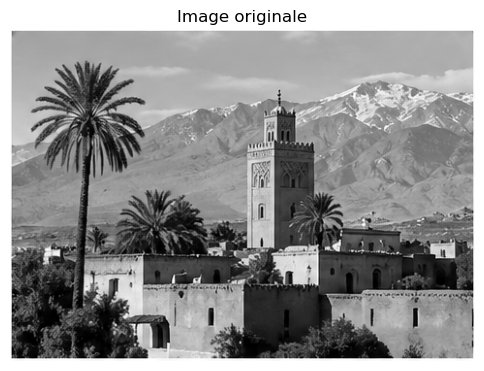

In [21]:
plt.figure(figsize=(6, 5))
plt.imshow(image_origine, cmap="gray")
plt.title("Image originale")
plt.axis("off")
plt.show()

1. Afficher et analyser l’histogramme d’une image donnée.

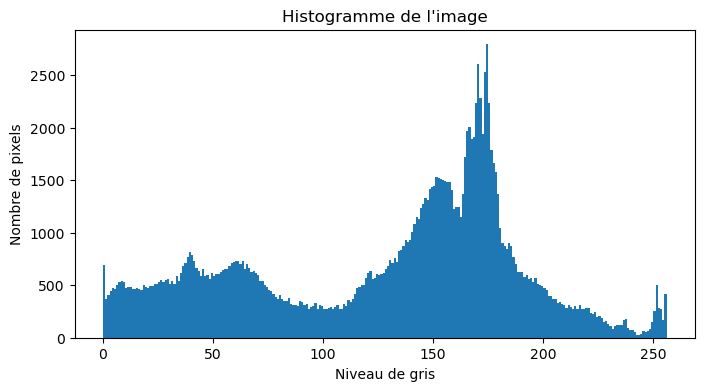

In [22]:
plt.figure(figsize=(8, 4))

plt.hist(image_origine.ravel(), bins=256, range=[0, 256])

plt.title("Histogramme de l'image")
plt.xlabel("Niveau de gris")
plt.ylabel("Nombre de pixels")
plt.show()

2. Appliquer un étirement linéaire et comparer l’effet sur le contraste.

In [23]:
min_val = np.min(image_origine)
max_val = np.max(image_origine)

stretched = ((image_origine - min_val) / (max_val - min_val) * 255)

stretched = stretched.astype(np.uint8)

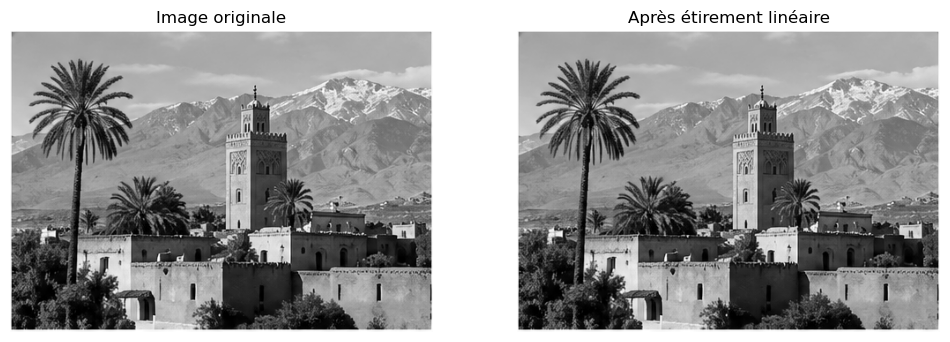

In [24]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.imshow(image_origine, cmap="gray")
plt.title("Image originale")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(stretched, cmap="gray")
plt.title("Après étirement linéaire")
plt.axis("off")

plt.show()

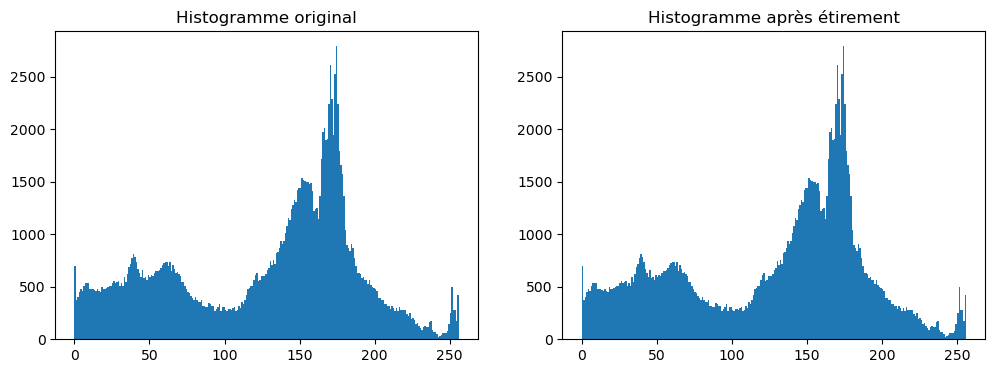

In [25]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.hist(image_origine.ravel(), bins=256, range=[0, 256])
plt.title("Histogramme original")

plt.subplot(1, 2, 2)
plt.hist(stretched.ravel(), bins=256, range=[0, 256])
plt.title("Histogramme après étirement")

plt.show()

3. Égalisation de l'histogramme

In [27]:
equalized = cv2.equalizeHist(image_origine)

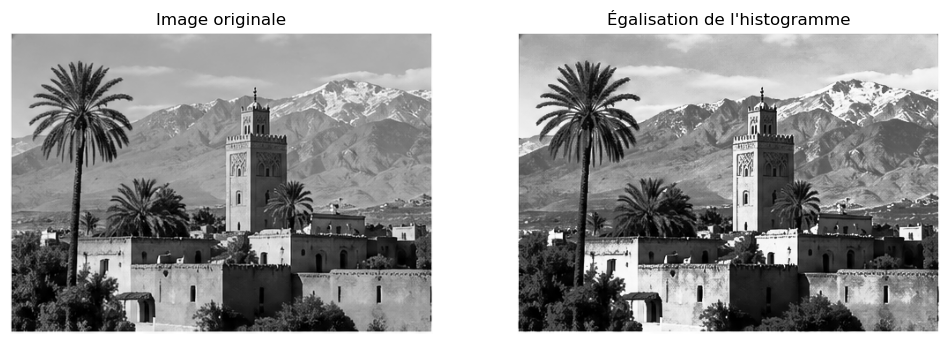

In [29]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.imshow(image_origine, cmap="gray")
plt.title("Image originale")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(equalized, cmap="gray")
plt.title("Égalisation de l'histogramme")
plt.axis("off")

plt.show()

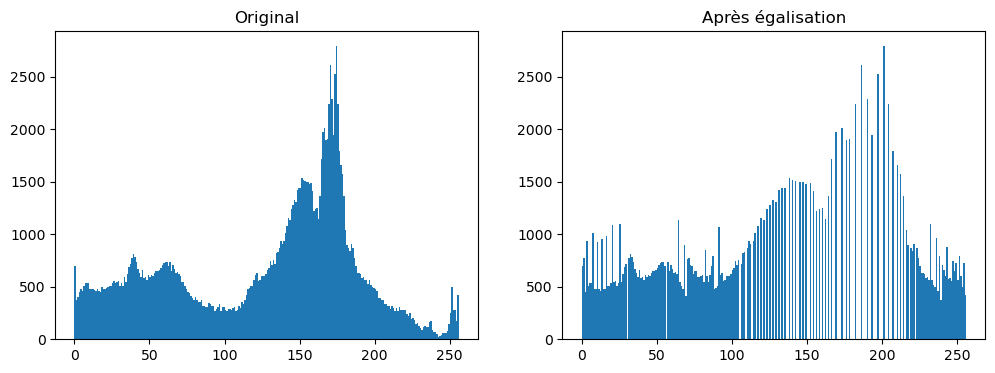

In [30]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.hist(image_origine.ravel(), bins=256, range=[0, 256])
plt.title("Original")

plt.subplot(1, 2, 2)
plt.hist(equalized.ravel(), bins=256, range=[0, 256])
plt.title("Après égalisation")

plt.show()

#### Différence
##### Étirement linéaire :
- étend les niveaux existants ;
- simple ;
- intéressant lorsque l'image a un contraste faible mais relativement uniforme.
##### Égalisation :
- redistribue les niveaux de gris ;
- peut améliorer davantage certaines images ;
- peut cependant amplifier le bruit.

## Exercice 2 : Seuillage
1. Effectuer un seuillage global fixe et observer le résultat.
2. Appliquer le seuillage automatique d’Otsu et comparer avec le global.
3. Appliquer le seuillage adaptatif (moyenne et gaussien) et observer les différences.

In [35]:
T = 127

_, threshold_global = cv2.threshold(
    image_origine,
    T,
    255,
    cv2.THRESH_BINARY
)

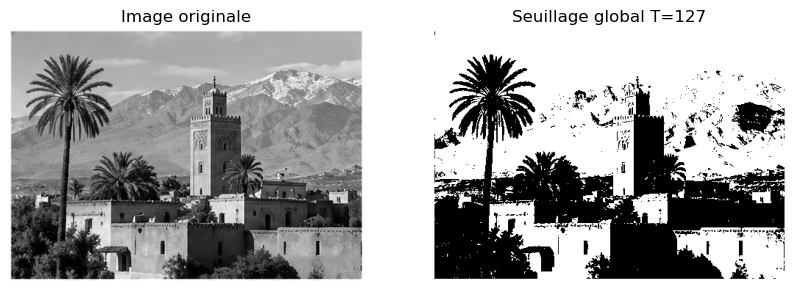

In [33]:
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.imshow(image_origine, cmap="gray")
plt.title("Image originale")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(threshold_global, cmap="gray")
plt.title("Seuillage global T=127")
plt.axis("off")

plt.show()

### 2. Seuillage automatique d'Otsu

In [36]:
T_otsu, threshold_otsu = cv2.threshold(
    image_origine,
    0,
    255,
    cv2.THRESH_BINARY + cv2.THRESH_OTSU
)

print("Seuil choisi par Otsu :", T_otsu)

Seuil choisi par Otsu : 107.0
